In [1]:
%pip install statsmodels

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [2]:
from insurance_pricing import data, split, preprocessing, config
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf

In [3]:
df = data.load_processed()

In [4]:
df

,ID,Date_last_renewal,Distribution_channel,Payment,Cost_claims_year,N_claims_year,Type_risk,Area,Second_driver,Power,...,Value_vehicle,N_doors,Type_fuel,Length,Weight,exposure,driver_age,licence_years,vehicle_age,renewal_year
0,1,2015-11-05,0,0,0.0,0,1,0,0,80,...,7068.00,0,P,NaN,190,1.000000,59.597260,39.654795,11,2015
1,1,2016-11-05,0,0,0.0,0,1,0,0,80,...,7068.00,0,P,NaN,190,1.000000,60.600000,40.657534,12,2016
2,1,2017-11-05,0,0,0.0,0,1,0,0,80,...,7068.00,0,P,NaN,190,1.000000,61.600000,41.657534,13,2017
3,1,2018-11-05,0,0,0.0,0,1,0,0,80,...,7068.00,0,P,NaN,190,0.153425,62.600000,42.657534,14,2018
4,2,2017-09-26,0,1,0.0,0,1,0,0,80,...,7068.00,0,P,NaN,190,1.000000,61.490411,41.547945,13,2017
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
105550,53498,2018-07-30,0,0,0.0,0,3,0,0,110,...,24320.00,5,D,4.740,1480,0.421918,37.038356,11.463014,18,2018
105551,53499,2018-08-16,0,0,0.0,0,3,0,0,129,...,30861.97,5,P,4.650,1440,0.375342,41.715068,0.712329,5,2018
105552,53500,2018-11-21,0,1,0.0,0,3,0,0,55,...,7800.00,5,P,3.495,830,0.109589,44.671233,7.134247,19,2018
105553,53501,2018-11-21,0,0,0.0,0,2,0,0,90,...,16610.00,5,D,4.555,1399,0.109589,72.232877,36.824658,14,2018


In [5]:
df = split.assign_split(df)

In [6]:
split.groups_are_disjoint(df)

True

In [7]:
split.split_summary(df)

,num_of_ids,num_of_rows,sum_claims,sum_exposure,row_share,frequency
split,,,,,,
train,32101,63390,24835,52259.279452,0.600540,0.475227
val,10700,21102,8422,17430.279452,0.199915,0.483182
test,10701,21063,8405,17350.753425,0.199545,0.484417


In [8]:
train = split.get_split(df, "train")
val = split.get_split(df, "val")
test = split.get_split(df, "test")

In [9]:
prep = preprocessing.GLMPreprocessor().fit(train)

In [10]:
X_train = prep.transform(train)
X_val = prep.transform(val)
X_test = prep.transform(test)

In [11]:
list(X_train.columns) == list(X_val.columns) == list(X_test.columns)

True

In [12]:
np.linalg.matrix_rank(X_train.to_numpy()), X_train.shape[1]

(np.int64(43), 43)

In [13]:
prep.reference_levels_

{'driver_age': '(34, 40.45]',
 'licence_years': '(17.58, 23.9]',
 'vehicle_age': '(6, 10]',
 'Power': '(65, 80]',
 'Value_vehicle': '(1.144e+04, 1.475e+04]',
 'Weight': '(-inf, 970]',
 'Type_risk': '3',
 'Area': '0',
 'Second_driver': '0',
 'Type_fuel': 'D',
 'Distribution_channel': '0',
 'Payment': '0',
 'renewal_year': '2017'}

In [14]:
glm = sm.GLM(
    train[config.N_CLAIMS_COL],
    X_train,
    family=sm.families.Poisson(),
    exposure=train[config.EXPOSURE_COL],
)
res = glm.fit()
res.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                 Generalized Linear Model Regression Results                  
==============================================================================
Dep. Variable:          N_claims_year   No. Observations:                63390
Model:                            GLM   Df Residuals:                    63347
Model Family:                 Poisson   Df Model:                           42
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -55107.
Date:                Sun, 08 Nov 2026   Deviance:                       81006.
Time:                        12:46:00   Pearson chi2:                 1.53e+05
No. Iterations:                    25   Pseudo R-squ. (CS):             0.1288
Covariance Type:            nonrobust                                         
========================================================================================================
                                           coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------------------
intercept                               -1.4849      0.044    -33.430      0.000      -1.572      -1.398
driver_age=(-inf, 34]                    0.0149      0.024      0.614      0.539      -0.033       0.063
driver_age=(40.45, 46.88]                0.0361      0.024      1.517      0.129      -0.011       0.083
driver_age=(46.88, 53.33]                0.1218      0.027      4.479      0.000       0.068       0.175
driver_age=(53.33, 60.41]                0.0500      0.031      1.632      0.103      -0.010       0.110
driver_age=(60.41, inf]                 -0.1072      0.036     -2.940      0.003      -0.179      -0.036
licence_years=(-inf, 11.56]              0.2575      0.026      9.802      0.000       0.206       0.309
licence_years=(11.56, 17.58]             0.0631      0.024      2.652      0.008       0.016       0.110
licence_years=(23.9, 30.48]              0.0849      0.024      3.520      0.000       0.038       0.132
licence_years=(30.48, 38.21]             0.0219      0.028      0.774      0.439      -0.034       0.077
licence_years=(38.21, inf]              -0.0459      0.035     -1.310      0.190      -0.114       0.023
vehicle_age=(-inf, 6]                    0.0139      0.021      0.666      0.505      -0.027       0.055
vehicle_age=(10, 12]                     0.0603      0.021      2.918      0.004       0.020       0.101
vehicle_age=(12, 14]                     0.1677      0.021      7.890      0.000       0.126       0.209
vehicle_age=(14, 17]                     0.1943      0.021      9.381      0.000       0.154       0.235
vehicle_age=(17, inf]                    0.0668      0.026      2.580      0.010       0.016       0.118
Power=(-inf, 65]                         0.0309      0.030      1.046      0.296      -0.027       0.089
Power=(80, 90]                          -0.0449      0.024     -1.887      0.059      -0.092       0.002
Power=(90, 105]                         -0.0266      0.025     -1.079      0.281      -0.075       0.022
Power=(105, 120]                        -0.0961      0.026     -3.662      0.000      -0.147      -0.045
Power=(120, inf]                        -0.0927      0.029     -3.177      0.001      -0.150      -0.036
Value_vehicle=(-inf, 1.144e+04]         -0.2090      0.035     -5.974      0.000      -0.278      -0.140
Value_vehicle=(1.475e+04, 1.765e+04]     0.0107      0.026      0.417      0.676      -0.040       0.061
Value_vehicle=(1.765e+04, 2.081e+04]     0.0745      0.030      2.489      0.013       0.016       0.133
Value_vehicle=(2.081e+04, 2.525e+04]     0.2133      0.033      6.505      0.000       0.149       0.278
Value_vehicle=(2.525e+04, inf]           0.2896      0.037      7.815      0.000       0.217       0.362
Weight=(970, 1100]                    

In [15]:
ci = res.conf_int()
rel = pd.DataFrame({
    "beta": res.params,
    "se": res.bse,
    "relativity": np.exp(res.params),
    "ci_lower": np.exp(ci[0]),
    "ci_upper": np.exp(ci[1]),
    "exposure": X_train.T @ train[config.EXPOSURE_COL],
    "claims": X_train.T @ train[config.N_CLAIMS_COL],
})
rel.sort_values("se", ascending=False).round(3)

/usr/lib64/python3.14/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: overflow encountered in exp
  result = getattr(ufunc, method)(*inputs, **kwargs)


,beta,se,relativity,ci_lower,ci_upper,exposure,claims
Type_risk=4,-25.474,14252.387,0.000,0.000,inf,414.603,0.0
Type_fuel=unknown,0.319,0.090,1.375,1.154,1.639,816.926,176.0
Type_risk=1,-0.564,0.052,0.569,0.514,0.630,4152.049,699.0
"Weight=(1455, inf]",0.152,0.046,1.165,1.065,1.274,8645.800,5561.0
intercept,-1.485,0.044,0.227,0.208,0.247,52259.279,24835.0
"Weight=(1312, 1455]",0.040,0.043,1.041,0.958,1.132,8659.197,4790.0
"Weight=(1205, 1312]",0.056,0.041,1.058,0.976,1.146,8656.282,4581.0
"Weight=(1100, 1205]",-0.084,0.038,0.919,0.854,0.990,8768.701,3875.0
"Value_vehicle=(2.525e+04, inf]",0.290,0.037,1.336,1.242,1.437,8568.929,5095.0
"driver_age=(60.41, inf]",-0.107,0.036,0.898,0.836,0.965,8661.948,2941.0


In [16]:
%pip install scikit-learn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [17]:
from insurance_pricing import metrics, models, plots

In [18]:
fitted = {
    "always 0": models.AlwaysZero().fit(X_train, train),
    "constant frequency": models.ConstantFrequency().fit(X_train, train),
    "ridge on frequency": models.RidgeFrequency(alpha=1.0).fit(X_train, train),
    "Poisson GLM": models.PoissonGLM().fit(X_train, train),
}

In [19]:
np.allclose(fitted["Poisson GLM"].result_.params, res.params)

True

In [20]:
y_val = val[config.N_CLAIMS_COL].to_numpy()
e_val = val[config.EXPOSURE_COL].to_numpy()
rate_train = models.base_rate(train)

pred_val = {name: m.predict(X_val, val) for name, m in fitted.items()}

In [21]:
results_val = metrics.metrics_table(y_val, e_val, pred_val, base_rate=rate_train)
results_val.round(4)

,mean_deviance,D2,MSE,MAE,pred_obs_ratio,gini
always 0,inf,-inf,1.4501,0.3991,0.0000,-0.0000
constant frequency,1.4504,0.0000,1.2647,0.6274,0.9835,-0.0000
ridge on frequency,NaN,NaN,1.2013,0.5843,0.9768,0.3382
Poisson GLM,1.3055,0.0999,1.1983,0.5814,0.9793,0.3395


In [22]:
ridge_pred = pred_val["ridge on frequency"]
n_negative = int((ridge_pred < 0).sum())
n_negative, n_negative / len(ridge_pred)

(1075, 0.050943038574542694)

In [23]:
metrics.calibration_table(y_val, pred_val["Poisson GLM"], e_val).round(4)

,claims,predicted,exposure,observed_freq,predicted_freq
group,,,,,
0,184.0,208.1473,1742.8904,0.1056,0.1194
1,328.0,360.9136,1742.9425,0.1882,0.2071
2,475.0,452.9606,1743.0493,0.2725,0.2599
3,517.0,547.2970,1742.7562,0.2967,0.3140
4,661.0,648.8617,1743.1945,0.3792,0.3722
5,828.0,762.0037,1743.4274,0.4749,0.4371
6,930.0,894.8043,1743.1945,0.5335,0.5133
7,1130.0,1056.2611,1742.3507,0.6485,0.6062
8,1424.0,1334.1378,1743.6082,0.8167,0.7652


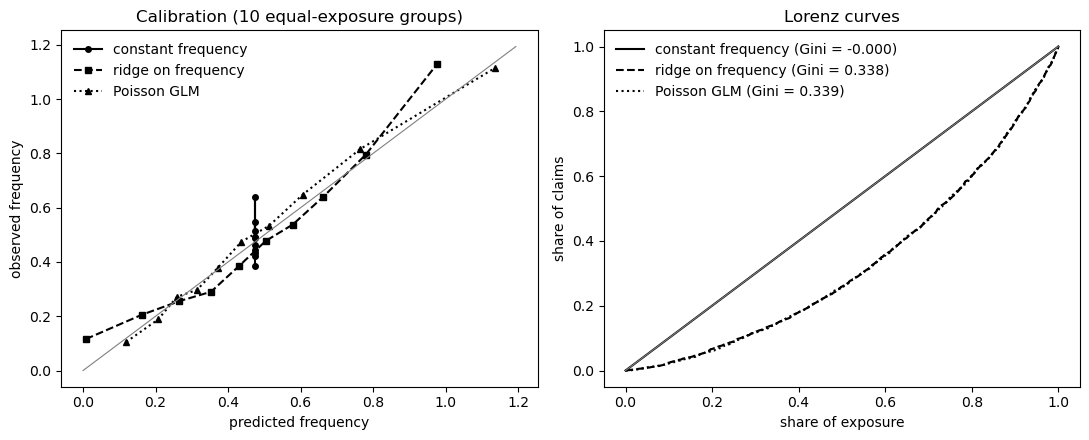

In [24]:
fig = plots.calibration_and_lorenz(
    y_val, e_val, {k: v for k, v in pred_val.items() if k != "always 0"}
)
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(config.FIGURES_DIR / "calibration_lorenz_val.png", dpi=200, bbox_inches="tight")